In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load only development data
df = pd.read_csv("../data/dev.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (120000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,0,0.114987,62,0,1841.000000,NaN,5,0,1,0,2.0
1,0,0.008705,73,0,0.498553,3800.0,6,0,1,0,0.0
2,0,0.214501,32,0,0.211999,3716.0,8,0,0,0,2.0
3,0,1.000000,60,0,118.000000,NaN,5,0,0,0,0.0
4,0,0.230493,60,0,1.017328,3000.0,10,0,1,0,0.0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dev = pd.read_csv("../data/dev.csv")

# Separate target and features
y = dev["SeriousDlqin2yrs"]
X = dev.drop(columns=["SeriousDlqin2yrs"])

print("Dataset shape:", dev.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True))

Dataset shape: (120000, 11)
Features shape: (120000, 10)
Target shape: (120000,)

Target distribution:
SeriousDlqin2yrs
0    0.933158
1    0.066842
Name: proportion, dtype: float64


In [3]:
dev = pd.read_csv("../data/dev.csv")

print(dev.columns.tolist())
print(dev.shape)

['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']
(120000, 11)


In [4]:
dev.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      120000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  120000 non-null  float64
 2   age                                   120000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  120000 non-null  int64  
 4   DebtRatio                             120000 non-null  float64
 5   MonthlyIncome                         96325 non-null   float64
 6   NumberOfOpenCreditLinesAndLoans       120000 non-null  int64  
 7   NumberOfTimes90DaysLate               120000 non-null  int64  
 8   NumberRealEstateLoansOrLines          120000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  120000 non-null  int64  
 10  NumberOfDependents                    116872 non-null  float64
dtypes: float64(

In [5]:
dev.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,120000.0,0.066842,0.249749,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,120000.0,6.128916,253.361490,0.0,0.029593,0.153318,0.557832,50708.0
age,120000.0,52.287842,14.771274,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,120000.0,0.420075,4.182138,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,120000.0,352.271245,2093.709509,0.0,0.175330,0.366194,0.860833,329664.0
MonthlyIncome,96325.0,6651.507345,14541.181413,0.0,3400.000000,5390.000000,8238.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,120000.0,8.465692,5.161693,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,120000.0,0.264942,4.158242,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,120000.0,1.018167,1.133055,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,120000.0,0.239858,4.144569,0.0,0.000000,0.000000,0.000000,98.0


In [6]:
dev.isna().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           23675
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3128
dtype: int64

In [7]:
dev.isna().mean() * 100

SeriousDlqin2yrs                         0.000000
RevolvingUtilizationOfUnsecuredLines     0.000000
age                                      0.000000
NumberOfTime30-59DaysPastDueNotWorse     0.000000
DebtRatio                                0.000000
MonthlyIncome                           19.729167
NumberOfOpenCreditLinesAndLoans          0.000000
NumberOfTimes90DaysLate                  0.000000
NumberRealEstateLoansOrLines             0.000000
NumberOfTime60-89DaysPastDueNotWorse     0.000000
NumberOfDependents                       2.606667
dtype: float64

In [8]:
missing = pd.DataFrame({
    "Missing_Count": dev.isna().sum(),
    "Missing_Percentage": dev.isna().mean() * 100
})

missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

,Missing_Count,Missing_Percentage
MonthlyIncome,23675,19.729167
NumberOfDependents,3128,2.606667
SeriousDlqin2yrs,0,0.000000
age,0,0.000000
RevolvingUtilizationOfUnsecuredLines,0,0.000000
DebtRatio,0,0.000000
NumberOfTime30-59DaysPastDueNotWorse,0,0.000000
NumberOfOpenCreditLinesAndLoans,0,0.000000
NumberOfTimes90DaysLate,0,0.000000
NumberRealEstateLoansOrLines,0,0.000000


In [9]:
for col in ["MonthlyIncome", "NumberOfDependents"]:

    print(f"\n{col}")

    print("Missing count:", dev[col].isna().sum())

    print("Missing percentage:", dev[col].isna().mean() * 100)

    print("Default rate when missing:",
          y[dev[col].isna()].mean())

    print("Default rate when available:",
          y[dev[col].notna()].mean())


MonthlyIncome
Missing count: 23675
Missing percentage: 19.729166666666668
Default rate when missing: 0.05571277719112988
Default rate when available: 0.06957695302361797

NumberOfDependents
Missing count: 3128
Missing percentage: 2.6066666666666665
Default rate when missing: 0.04411764705882353
Default rate when available: 0.06744985967554247


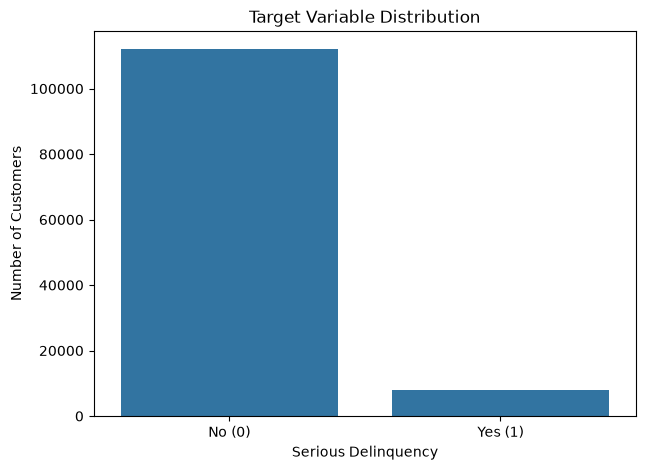

In [10]:
target_counts = dev["SeriousDlqin2yrs"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=target_counts.index,
    y=target_counts.values
)

plt.title("Target Variable Distribution")
plt.xlabel("Serious Delinquency")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["No (0)", "Yes (1)"])

plt.show()

In [11]:
print(target_counts)
print(dev["SeriousDlqin2yrs"].value_counts(normalize=True) * 100)

SeriousDlqin2yrs
0    111979
1      8021
Name: count, dtype: int64
SeriousDlqin2yrs
0    93.315833
1     6.684167
Name: proportion, dtype: float64


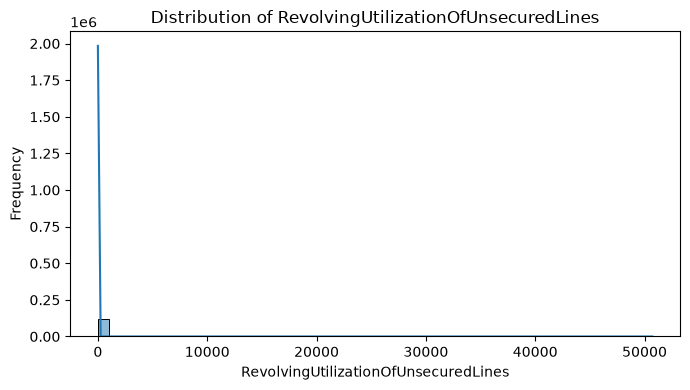

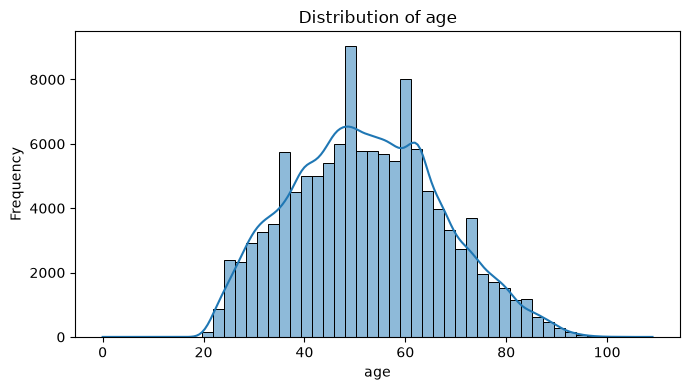

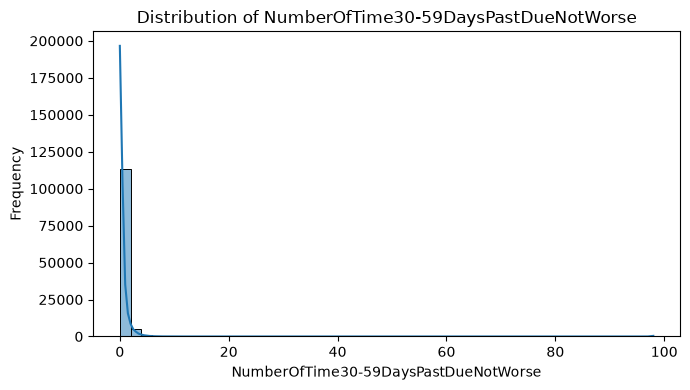

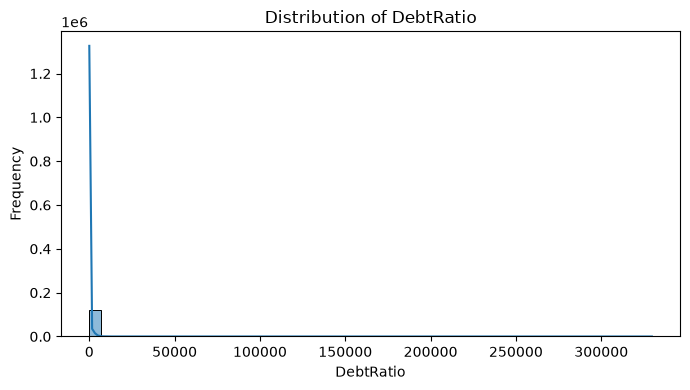

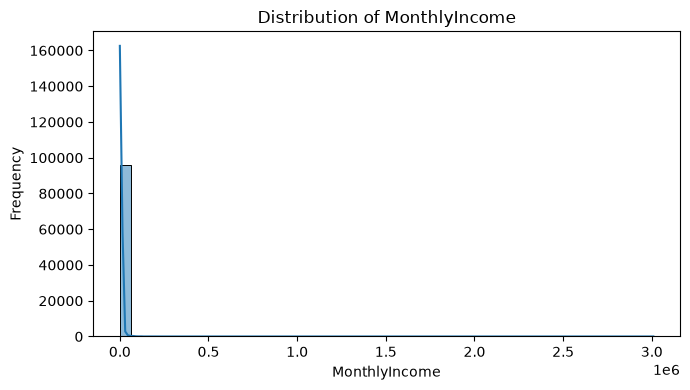

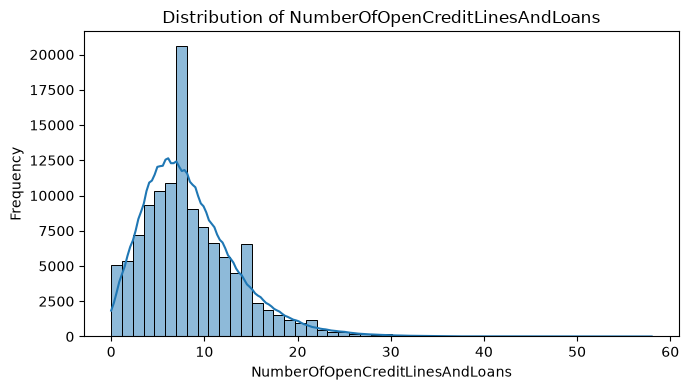

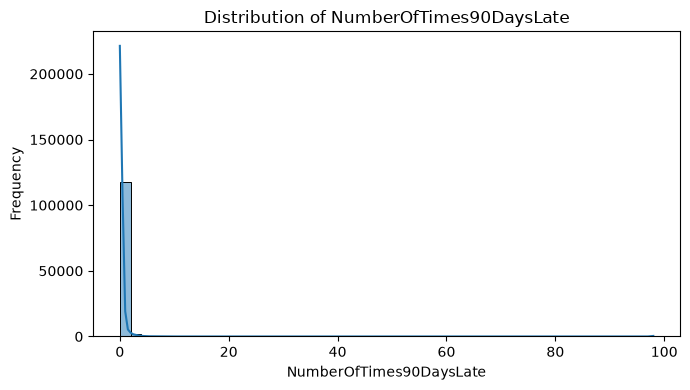

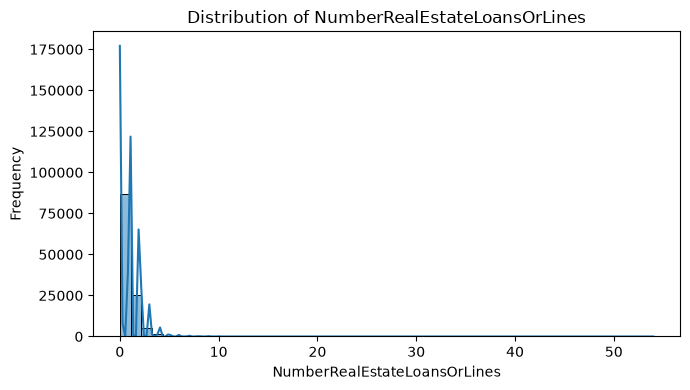

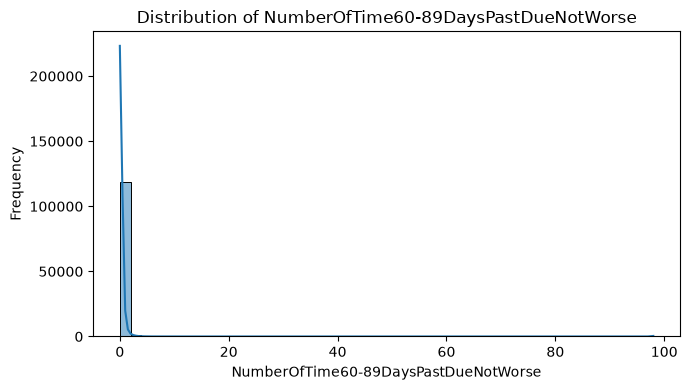

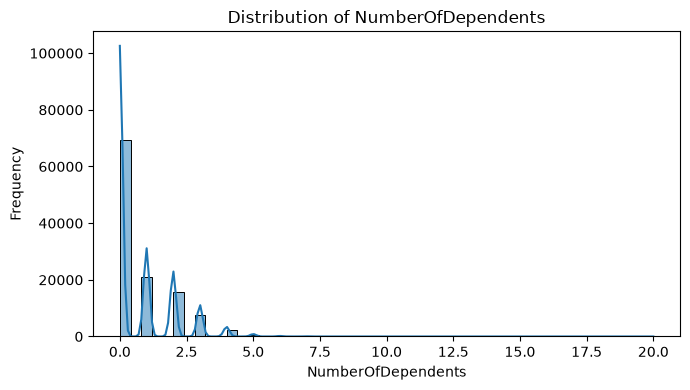

In [12]:
features = X.columns.tolist()

for col in features:
    plt.figure(figsize=(7, 4))

    sns.histplot(dev[col].dropna(), bins=50, kde=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [13]:
print("Age minimum:", dev["age"].min())

print(
    "Revolving utilization maximum:",
    dev["RevolvingUtilizationOfUnsecuredLines"].max()
)

print("Debt ratio maximum:", dev["DebtRatio"].max())

Age minimum: 0
Revolving utilization maximum: 50708.0
Debt ratio maximum: 329664.0


In [14]:
late_columns = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse"
]

for col in late_columns:
    print(f"\n{col}")
    print(dev[col].value_counts().sort_index())


NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
0     100794
1      12844
2       3689
3       1421
4        581
5        266
6        108
7         44
8         21
9         10
10         4
11         1
12         2
13         1
96         2
98       212
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
0     113294
1       4230
2       1256
3        530
4        238
5        100
6         62
7         29
8         15
9         13
10         7
11         3
12         1
13         3
14         2
15         2
17         1
96         2
98       212
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
0     113881
1       4626
2        883
3        254
4         91
5         27
6         13
7          8
8          1
9          1
11         1
96         2
98       212
Name: count, dtype: int64


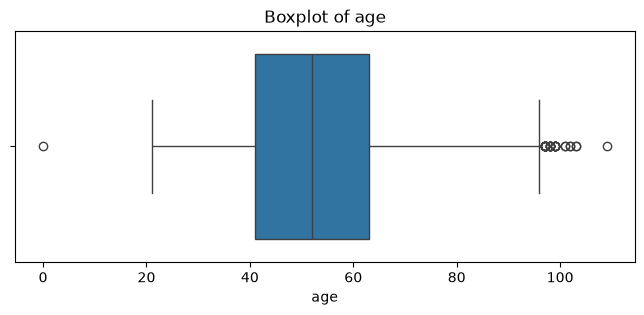

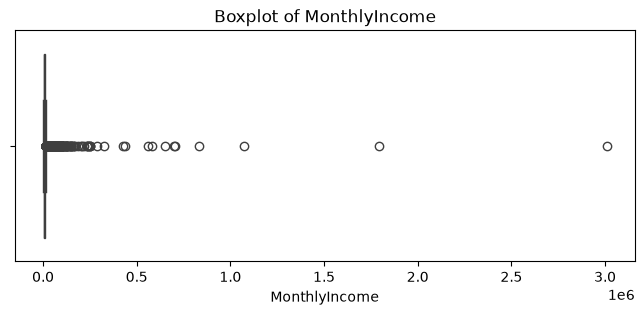

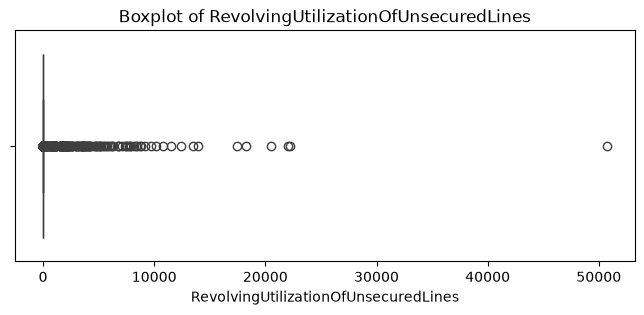

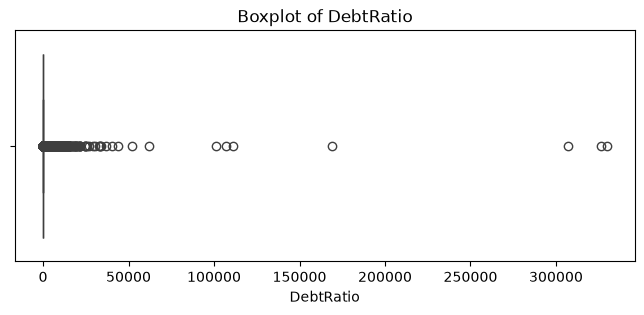

In [15]:
check_features = [
    "age",
    "MonthlyIncome",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio"
]

for col in check_features:
    plt.figure(figsize=(8, 3))

    sns.boxplot(x=dev[col])

    plt.title(f"Boxplot of {col}")
    plt.show()

In [16]:
late_columns = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse"
]

for col in late_columns:
    print(f"\n{col}")
    print(dev[col].value_counts().loc[lambda s: s.index.isin([96, 98])])


NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
98    212
96      2
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
98    212
96      2
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
98    212
96      2
Name: count, dtype: int64


In [17]:
dev[dev["age"] == 0]

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
64594,0,1.0,0,1,0.436927,6000.0,6,0,2,0,2.0


In [18]:
print("Top 10 Revolving Utilization:")
print(dev["RevolvingUtilizationOfUnsecuredLines"].nlargest(10))

print("\nTop 10 Debt Ratios:")
print(dev["DebtRatio"].nlargest(10))

Top 10 Revolving Utilization:
72149    50708.0
67967    22198.0
27390    22000.0
48941    20514.0
52172    18300.0
62739    17441.0
86501    13930.0
84400    13498.0
70603    12369.0
74774    11553.0
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

Top 10 Debt Ratios:
78491     329664.0
58966     326442.0
117072    307001.0
52466     168835.0
47492     110952.0
103478    106885.0
106796    101320.0
6058       61907.0
51889      52112.0
7407       43843.0
Name: DebtRatio, dtype: float64


In [19]:
# Investigate extreme revolving utilization
print("Extreme revolving utilization:")
print(dev.nlargest(10, "RevolvingUtilizationOfUnsecuredLines")[
    ["RevolvingUtilizationOfUnsecuredLines", "MonthlyIncome", "DebtRatio"]
])

# Investigate extreme debt ratios
print("\nExtreme debt ratios:")
print(dev.nlargest(10, "DebtRatio")[
    ["DebtRatio", "MonthlyIncome", "RevolvingUtilizationOfUnsecuredLines"]
])

# Check zero monthly income
print("\nZero monthly income:")
print((dev["MonthlyIncome"] == 0).sum())

Extreme revolving utilization:
       RevolvingUtilizationOfUnsecuredLines  MonthlyIncome    DebtRatio
72149                               50708.0        38000.0     0.221757
67967                               22198.0            NaN  2312.000000
27390                               22000.0         3973.0     1.080020
48941                               20514.0         9902.0     0.062102
52172                               18300.0        12500.0     0.221582
62739                               17441.0        14770.0     0.354072
86501                               13930.0            NaN  4902.000000
84400                               13498.0         4800.0     0.347428
70603                               12369.0        30300.0     0.134352
74774                               11553.0            NaN  3742.000000

Extreme debt ratios:
        DebtRatio  MonthlyIncome  RevolvingUtilizationOfUnsecuredLines
78491    329664.0            NaN                              0.000000
58966    3264

In [20]:
late_columns = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse"
]

for col in late_columns:
    print(f"\n{col}")
    print(dev[col].value_counts().sort_index())


NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
0     100794
1      12844
2       3689
3       1421
4        581
5        266
6        108
7         44
8         21
9         10
10         4
11         1
12         2
13         1
96         2
98       212
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
0     113294
1       4230
2       1256
3        530
4        238
5        100
6         62
7         29
8         15
9         13
10         7
11         3
12         1
13         3
14         2
15         2
17         1
96         2
98       212
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
0     113881
1       4626
2        883
3        254
4         91
5         27
6         13
7          8
8          1
9          1
11         1
96         2
98       212
Name: count, dtype: int64


In [21]:
for col in late_columns:
    print(f"\n{col}")

    for value in [96, 98]:
        rows = dev[dev[col] == value]

        print(
            f"Value {value}:",
            len(rows),
            "Target rate:",
            rows["SeriousDlqin2yrs"].mean()
        )


NumberOfTime30-59DaysPastDueNotWorse
Value 96: 2 Target rate: 1.0
Value 98: 212 Target rate: 0.5424528301886793

NumberOfTimes90DaysLate
Value 96: 2 Target rate: 1.0
Value 98: 212 Target rate: 0.5424528301886793

NumberOfTime60-89DaysPastDueNotWorse
Value 96: 2 Target rate: 1.0
Value 98: 212 Target rate: 0.5424528301886793


In [22]:
late_columns = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse"
]

# Check customers having 96 or 98 in all three columns
for value in [96, 98]:
    mask = (dev[late_columns] == value).all(axis=1)

    print(f"\nCustomers with {value} in all three columns:")
    print(mask.sum())

# Check customers having these values in at least one column
for value in [96, 98]:
    mask = (dev[late_columns] == value).any(axis=1)

    print(f"\nCustomers with {value} in at least one column:")
    print(mask.sum())


Customers with 96 in all three columns:
2

Customers with 98 in all three columns:
212

Customers with 96 in at least one column:
2

Customers with 98 in at least one column:
212


In [23]:
import pandas as pd

file_path = "../data/Data Dictionary.xls"

xls = pd.ExcelFile(file_path)

print("Available sheets:", xls.sheet_names)

for sheet in xls.sheet_names:
    dictionary = pd.read_excel(file_path, sheet_name=sheet)
    print(f"\nSheet: {sheet}")
    display(dictionary.head(15))

Available sheets: ['Sheet1', 'Sheet2', 'Sheet3']

Sheet: Sheet1


C:\Users\HP\AppData\Local\Temp\ipykernel_3880\1296479267.py:5: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  xls = pd.ExcelFile(file_path)
C:\Users\HP\AppData\Local\Temp\ipykernel_3880\1296479267.py:10: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  dictionary = pd.read_excel(file_path, sheet_name=sheet)


,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,Variable Name,Description,Type
1,SeriousDlqin2yrs,Person experienced 90 days past due delinquenc...,Y/N
2,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lin...,percentage
3,age,Age of borrower in years,integer
4,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days p...,integer
5,DebtRatio,"Monthly debt payments, alimony,living costs di...",percentage
6,MonthlyIncome,Monthly income,real
7,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loa...,integer
8,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or m...,integer
9,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans inclu...,integer



Sheet: Sheet2


C:\Users\HP\AppData\Local\Temp\ipykernel_3880\1296479267.py:10: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  dictionary = pd.read_excel(file_path, sheet_name=sheet)


""



Sheet: Sheet3


C:\Users\HP\AppData\Local\Temp\ipykernel_3880\1296479267.py:10: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  dictionary = pd.read_excel(file_path, sheet_name=sheet)


""


In [24]:
for sheet in ["Sheet2", "Sheet3"]:
    print(f"\n{'='*20} {sheet} {'='*20}")

    dictionary = pd.read_excel(
        file_path,
        sheet_name=sheet,
        header=None
    )

    display(dictionary)


==================== Sheet2 ====================


C:\Users\HP\AppData\Local\Temp\ipykernel_3880\4156756412.py:4: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  dictionary = pd.read_excel(


""



==================== Sheet3 ====================


C:\Users\HP\AppData\Local\Temp\ipykernel_3880\4156756412.py:4: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  dictionary = pd.read_excel(


""


In [25]:
for sheet in ["Sheet2", "Sheet3"]:
    dictionary = pd.read_excel(
        file_path,
        sheet_name=sheet,
        header=None
    )

    print(f"{sheet} shape:", dictionary.shape)
    print(f"{sheet} non-empty rows:")
    display(dictionary.dropna(how="all"))

Sheet2 shape: (0, 0)
Sheet2 non-empty rows:


C:\Users\HP\AppData\Local\Temp\ipykernel_3880\4196608633.py:2: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  dictionary = pd.read_excel(


""


Sheet3 shape: (0, 0)
Sheet3 non-empty rows:


C:\Users\HP\AppData\Local\Temp\ipykernel_3880\4196608633.py:2: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  dictionary = pd.read_excel(


""


In [26]:
for col in [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]:
    print(col)
    print(dev[col].value_counts().head(20))
    print("default rate if >=96:", y[dev[col] >= 96].mean())
    print("default rate if <96:", y[dev[col] < 96].mean())
    print("---")

NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
0     100794
1      12844
2       3689
3       1421
4        581
5        266
98       212
6        108
7         44
8         21
9         10
10         4
96         2
12         2
13         1
11         1
Name: count, dtype: int64
default rate if >=96: 0.5467289719626168
default rate if <96: 0.06598433873741506
---
NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
0     113881
1       4626
2        883
3        254
98       212
4         91
5         27
6         13
7          8
96         2
9          1
11         1
8          1
Name: count, dtype: int64
default rate if >=96: 0.5467289719626168
default rate if <96: 0.06598433873741506
---
NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
0     113294
1       4230
2       1256
3        530
4        238
98       212
5        100
6         62
7         29
8         15
9         13
10         7
13         3
11         3
15         2
96      

In [27]:
print(y[dev["MonthlyIncome"].isna()].mean())
print(y[dev["MonthlyIncome"].notna()].mean())

0.05571277719112988
0.06957695302361797


In [28]:
dev["MonthlyIncome_missing"] = dev["MonthlyIncome"].isna().astype(int)

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

age_bins = [-1, 25, 35, 45, 55, 65, 120]

age_groups = pd.cut(dev["age"], bins=age_bins)

age_default_rate = y.groupby(age_groups, observed=False).mean()

print(age_default_rate)

age
(-1, 25]     0.109935
(25, 35]     0.108688
(35, 45]     0.088126
(45, 55]     0.076136
(55, 65]     0.046733
(65, 120]    0.024639
Name: SeriousDlqin2yrs, dtype: float64


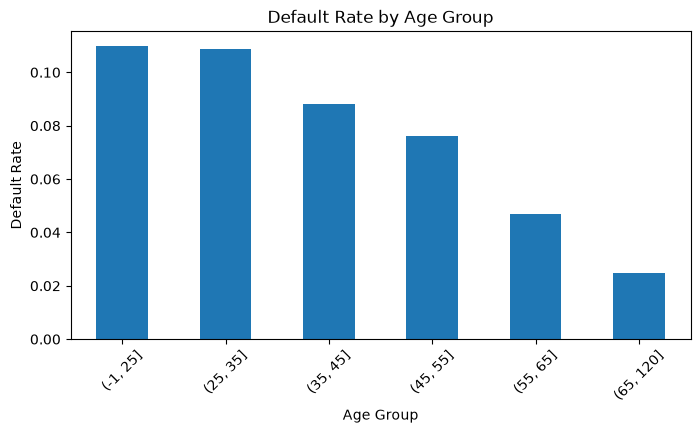

In [30]:
age_default_rate.plot(kind="bar", figsize=(8, 4))

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate")
plt.xticks(rotation=45)
plt.show()

RevolvingUtilizationOfUnsecuredLines
(-0.001, 0.3]    0.022260
(0.3, 0.6]       0.066309
(0.6, 0.9]       0.134917
(0.9, 1.0]       0.193081
(1.0, inf]       0.375000
Name: SeriousDlqin2yrs, dtype: float64


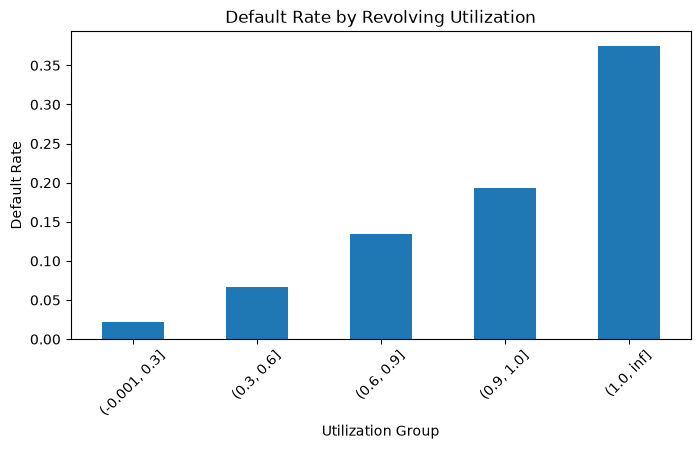

In [31]:
util_bins = [-0.001, 0.3, 0.6, 0.9, 1, float("inf")]

util_groups = pd.cut(
    dev["RevolvingUtilizationOfUnsecuredLines"],
    bins=util_bins
)

util_default_rate = y.groupby(util_groups, observed=False).mean()

print(util_default_rate)

util_default_rate.plot(kind="bar", figsize=(8, 4))
plt.title("Default Rate by Revolving Utilization")
plt.xlabel("Utilization Group")
plt.ylabel("Default Rate")
plt.xticks(rotation=45)
plt.show()

In [32]:
print("Age group counts:")
print(y.groupby(age_groups, observed=False).count())

print("\nUtilization group counts:")
print(y.groupby(util_groups, observed=False).count())

Age group counts:
age
(-1, 25]      2456
(25, 35]     14721
(35, 45]     23875
(45, 55]     29329
(55, 65]     26769
(65, 120]    22850
Name: SeriousDlqin2yrs, dtype: int64

Utilization group counts:
RevolvingUtilizationOfUnsecuredLines
(-0.001, 0.3]    74347
(0.3, 0.6]       17524
(0.6, 0.9]       12163
(0.9, 1.0]       13326
(1.0, inf]        2640
Name: SeriousDlqin2yrs, dtype: int64


In [33]:
dev["NumberOfDependents_missing"] = dev["NumberOfDependents"].isna().astype(int)

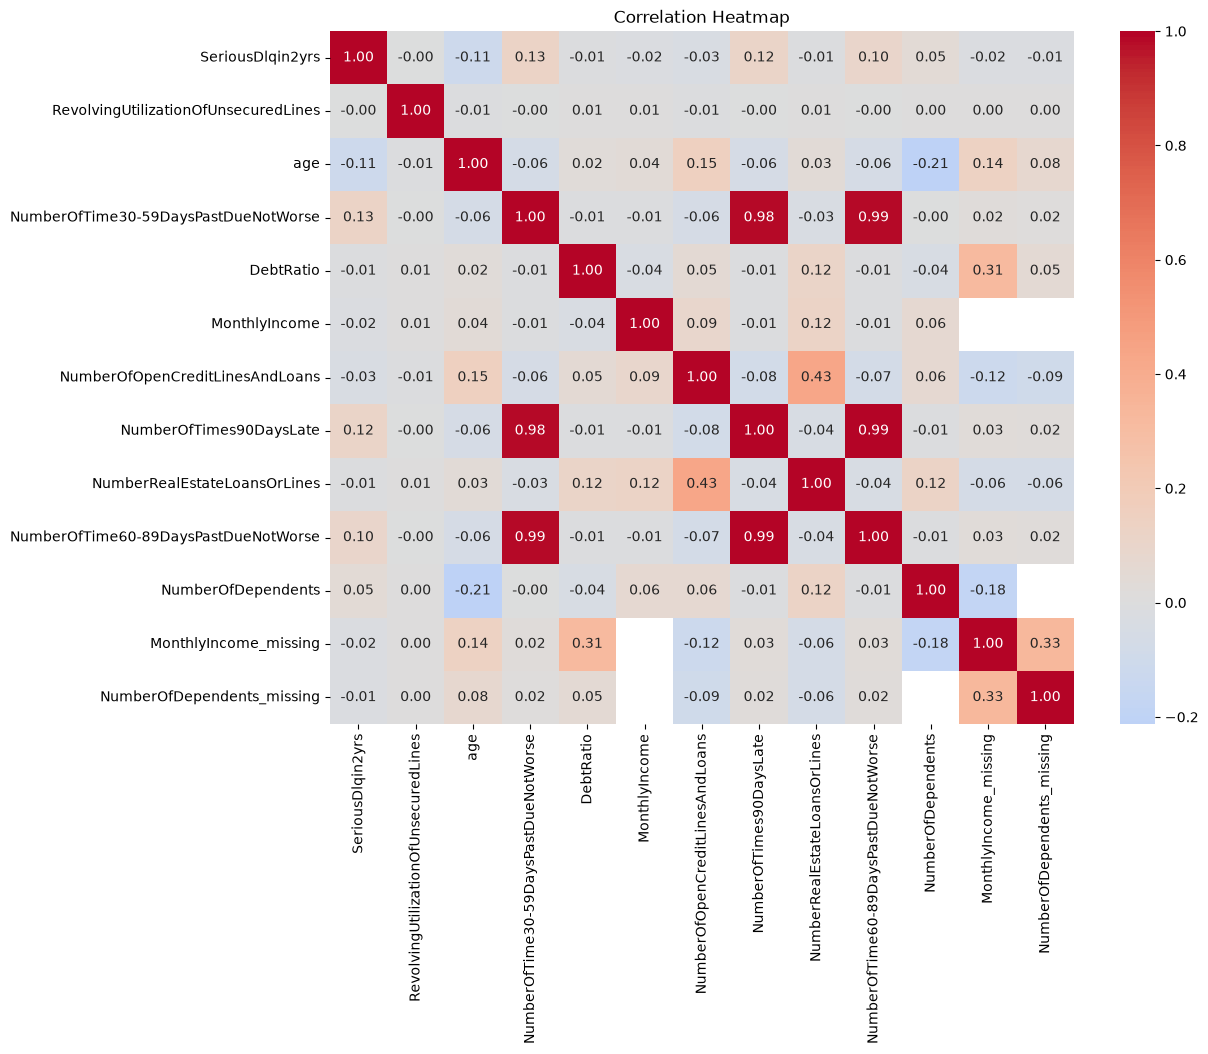

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = dev.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [35]:
corr = dev.corr(numeric_only=True)

corr_target = corr["SeriousDlqin2yrs"].drop(
    "SeriousDlqin2yrs"
)

# Separate positive and negative correlations
positive_corr = corr_target[corr_target > 0].sort_values(
    ascending=False
)

negative_corr = corr_target[corr_target < 0].sort_values()

print("Strongest positive correlations:")
print(positive_corr.head(5))

print("\nStrongest negative correlations:")
print(negative_corr.head(5))

Strongest positive correlations:
NumberOfTime30-59DaysPastDueNotWorse    0.125012
NumberOfTimes90DaysLate                 0.117131
NumberOfTime60-89DaysPastDueNotWorse    0.102294
NumberOfDependents                      0.045636
Name: SeriousDlqin2yrs, dtype: float64

Strongest negative correlations:
age                               -0.112322
NumberOfOpenCreditLinesAndLoans   -0.032654
MonthlyIncome_missing             -0.022092
MonthlyIncome                     -0.018634
NumberOfDependents_missing        -0.014885
Name: SeriousDlqin2yrs, dtype: float64


In [36]:
late_columns = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse"
]

late_corr = dev[late_columns].corr()

print("Correlations among late-payment features:")
print(late_corr)

Correlations among late-payment features:
                                      NumberOfTime30-59DaysPastDueNotWorse  \
NumberOfTime30-59DaysPastDueNotWorse                              1.000000   
NumberOfTimes90DaysLate                                           0.983642   
NumberOfTime60-89DaysPastDueNotWorse                              0.986941   

                                      NumberOfTimes90DaysLate  \
NumberOfTime30-59DaysPastDueNotWorse                 0.983642   
NumberOfTimes90DaysLate                              1.000000   
NumberOfTime60-89DaysPastDueNotWorse                 0.992823   

                                      NumberOfTime60-89DaysPastDueNotWorse  
NumberOfTime30-59DaysPastDueNotWorse                              0.986941  
NumberOfTimes90DaysLate                                           0.992823  
NumberOfTime60-89DaysPastDueNotWorse                              1.000000  


In [37]:
# Exclude rows containing sentinel values (96 and 98)
normal_late_data = dev[
    (dev[late_columns] < 96).all(axis=1)
]

# Calculate correlations again
late_corr_clean = normal_late_data[late_columns].corr()

print("Correlations after excluding sentinel values:")
print(late_corr_clean)

Correlations after excluding sentinel values:
                                      NumberOfTime30-59DaysPastDueNotWorse  \
NumberOfTime30-59DaysPastDueNotWorse                              1.000000   
NumberOfTimes90DaysLate                                           0.220923   
NumberOfTime60-89DaysPastDueNotWorse                              0.306186   

                                      NumberOfTimes90DaysLate  \
NumberOfTime30-59DaysPastDueNotWorse                 0.220923   
NumberOfTimes90DaysLate                              1.000000   
NumberOfTime60-89DaysPastDueNotWorse                 0.295939   

                                      NumberOfTime60-89DaysPastDueNotWorse  
NumberOfTime30-59DaysPastDueNotWorse                              0.306186  
NumberOfTimes90DaysLate                                           0.295939  
NumberOfTime60-89DaysPastDueNotWorse                              1.000000  
